# Laboratorium 6 — Warstwa łącząca (pooling) i pełna CNN


## 0. Instalacja i importy

In [1]:
!pip install -q torch torchvision matplotlib pandas

In [2]:
import os, shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__, "| urządzenie:", device,
      "|", torch.cuda.get_device_name(0) if device == "cuda" else "")

PyTorch: 2.14.1+cu130 | torchvision: 0.29.1+cu130 | urządzenie: cuda | Tesla T4


## 1. Konfiguracja
Wspólne ustawienia dla wszystkich wariantów. Dla CIFAR-10 wystarczy zmienić `DATASET`.

In [3]:
DATASET    = "FashionMNIST"   # "FashionMNIST" albo "CIFAR10"
EPOCHS     = 10
BATCH_SIZE = 128
LR         = 1e-3             # Adam
SEED       = 0
OUT_DIR    = "wyniki_lab06"
os.makedirs(OUT_DIR, exist_ok=True)

# powtarzalność
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## 2. Dane


In [4]:
if DATASET == "FashionMNIST":
    tr = torchvision.datasets.FashionMNIST("./data", train=True,  download=True)
    te = torchvision.datasets.FashionMNIST("./data", train=False, download=True)
    to_tensor = lambda d: d.data.unsqueeze(1).float() / 255.0                         # [N,1,28,28]
    MEAN, STD = (0.2860,), (0.3530,)
elif DATASET == "CIFAR10":
    tr = torchvision.datasets.CIFAR10("./data", train=True,  download=True)
    te = torchvision.datasets.CIFAR10("./data", train=False, download=True)
    to_tensor = lambda d: torch.from_numpy(d.data).permute(0, 3, 1, 2).float() / 255.0  # [N,3,32,32]
    MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

mean = torch.tensor(MEAN).view(1, -1, 1, 1); std = torch.tensor(STD).view(1, -1, 1, 1)
Xtr = ((to_tensor(tr) - mean) / std).to(device); Ytr = torch.as_tensor(tr.targets).to(device)
Xte = ((to_tensor(te) - mean) / std).to(device); Yte = torch.as_tensor(te.targets).to(device)
IN_CH, IMG, N_CLASSES = Xtr.shape[1], Xtr.shape[-1], len(tr.classes)
print(f"{DATASET}: train {tuple(Xtr.shape)}, test {tuple(Xte.shape)}, klas: {N_CLASSES}")

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.80MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.9MB/s]


FashionMNIST: train (60000, 1, 28, 28), test (10000, 1, 28, 28), klas: 10


## 3. Model

Klasa z ćwiczenia rozszerzona o parametry potrzebne w zakresie dodatkowym.

| parametr | znaczenie |
|---|---|
| `pool` | `"max"` / `"avg"` — pooling z krokiem 2; `"stride"` — splot 3×3, krok 2, padding 1 -> BN -> ReLU |
| `pool_k` | okno poolingu: 2 (bez paddingu) albo 3 (padding 1) |
| `n_blocks` | liczba bloków; kanały kolejno 32, 64, 128 |
| `head` | `"gap"`: GAP -> Flatten -> Linear; `"flatten"`: Flatten -> Linear |

Rozmiar mapy cech przed głowicą wyznaczany jest przebiegiem próbnym, więc uwzględnia różne zaokrąglenia: pooling zaokrągla w dół (7 -> 3), splot z krokiem i paddingiem 1 — w górę (7 -> 4).

In [5]:
class CNN(nn.Module):
    def __init__(self, pool="max", pool_k=2, n_blocks=2, head="gap"):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            if pool == "max":
                layers.append(nn.MaxPool2d(pool_k, stride=2, padding=(pool_k - 1) // 2))
            elif pool == "avg":
                layers.append(nn.AvgPool2d(pool_k, stride=2, padding=(pool_k - 1) // 2))
            elif pool == "stride":
                layers += [nn.Conv2d(cout, cout, 3, stride=2, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            else:
                raise ValueError(pool)
            return nn.Sequential(*layers)

        chans = [32, 64, 128][:n_blocks]
        self.features = nn.Sequential(*[block(cin, cout) for cin, cout in zip([IN_CH] + chans[:-1], chans)])

        # rzeczywisty rozmiar mapy cech przed głowicą
        self.features.eval()
        with torch.no_grad():
            C, H, W = self.features(torch.zeros(1, IN_CH, IMG, IMG)).shape[1:]
        self.features.train()
        self.feat_shape = [C, H, W]

        if head == "gap":
            self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(C, N_CLASSES))
        elif head == "flatten":
            self.head = nn.Sequential(nn.Flatten(), nn.Linear(C * H * W, N_CLASSES))
        else:
            raise ValueError(head)

    def forward(self, x):
        return self.head(self.features(x))

def count(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

### 3.1 Kontrola przed treningiem


In [6]:
CONFIGS = {
    # zakres obowiązkowy
    "max 2×2":          dict(pool="max"),
    "avg 2×2":          dict(pool="avg"),
    "stride 3×3/2":     dict(pool="stride"),
    # A: okno poolingu
    "max 3×3":          dict(pool="max", pool_k=3),
    "avg 3×3":          dict(pool="avg", pool_k=3),
    # B: głowica
    "max + flatten":    dict(pool="max",    head="flatten"),
    "avg + flatten":    dict(pool="avg",    head="flatten"),
    "stride + flatten": dict(pool="stride", head="flatten"),
    # C: liczba bloków
    "max, 1 blok":      dict(pool="max",    n_blocks=1),
    "max, 3 bloki":     dict(pool="max",    n_blocks=3),
    "avg, 1 blok":      dict(pool="avg",    n_blocks=1),
    "avg, 3 bloki":     dict(pool="avg",    n_blocks=3),
    "stride, 1 blok":   dict(pool="stride", n_blocks=1),
    "stride, 3 bloki":  dict(pool="stride", n_blocks=3),
}

rows = []
for name, cfg in CONFIGS.items():
    m = CNN(**cfg)
    rows.append({"konfiguracja": name, "mapa przed głowicą [C, H, W]": m.feat_shape,
                 "parametry głowicy": count(m.head), "parametry razem": count(m)})
pd.DataFrame(rows)

,konfiguracja,"mapa przed głowicą [C, H, W]",parametry głowicy,parametry razem
0,max 2×2,"[64, 7, 7]",650,19658
1,avg 2×2,"[64, 7, 7]",650,19658
2,stride 3×3/2,"[64, 7, 7]",650,66026
3,max 3×3,"[64, 7, 7]",650,19658
4,avg 3×3,"[64, 7, 7]",650,19658
5,max + flatten,"[64, 7, 7]",31370,50378
6,avg + flatten,"[64, 7, 7]",31370,50378
7,stride + flatten,"[64, 7, 7]",31370,96746
8,"max, 1 blok","[32, 14, 14]",330,714
9,"max, 3 bloki","[128, 3, 3]",1290,94410


## 4. Trening i ewaluacja

- Adam, entropia krzyżowa, `EPOCHS` epok; przed każdym przebiegiem ten sam seed (te same wagi początkowe dla tej samej architektury i ta sama kolejność batchy).
- Po każdej epoce accuracy na całym zbiorze treningowym i testowym w trybie `eval` — przerwa train–test jest mierzona w tych samych warunkach.
- Do tabel trafia accuracy po ostatniej epoce. Maksimum krzywej testowej podany jest w osobnej kolumnie z dopiskiem, bo jest to wybór modelu na zbiorze testowym.

In [7]:
@torch.no_grad()
def evaluate(model, X, Y, bs=2000):
    model.eval()
    correct = sum((model(X[i:i+bs]).argmax(1) == Y[i:i+bs]).sum().item() for i in range(0, len(X), bs))
    return correct / len(X)

RESULTS = {}

def train_variant(name, verbose=True):
    if name in RESULTS:
        return RESULTS[name]
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = CNN(**CONFIGS[name]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(SEED)
    hist = {"train_acc": [], "test_acc": []}
    for ep in range(1, EPOCHS + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=gen).to(device)
        for i in range(0, len(Xtr), BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            opt.zero_grad()
            F.cross_entropy(model(Xtr[idx]), Ytr[idx]).backward()
            opt.step()
        hist["train_acc"].append(evaluate(model, Xtr, Ytr))
        hist["test_acc"].append(evaluate(model, Xte, Yte))
        if verbose:
            print(f"[{name}] epoka {ep:2d}: train {hist['train_acc'][-1]*100:.2f}%  test {hist['test_acc'][-1]*100:.2f}%")
    RESULTS[name] = dict(hist=hist, params=count(model), head_params=count(model.head),
                         feat_shape=model.feat_shape)
    return RESULTS[name]

def results_table(names):
    rows = []
    for n in names:
        r = RESULTS[n]; tr_acc, te_acc = r["hist"]["train_acc"], r["hist"]["test_acc"]
        rows.append({
            "wariant": n,
            "parametry": r["params"],
            "parametry głowicy": r["head_params"],
            "mapa przed głowicą [C, H, W]": r["feat_shape"],
            "train acc [%]": round(tr_acc[-1] * 100, 2),
            "test acc [%]": round(te_acc[-1] * 100, 2),
            "przerwa train–test [p.p.]": round((tr_acc[-1] - te_acc[-1]) * 100, 2),
            "maks. test acc* [%] (epoka)": f"{max(te_acc)*100:.2f} ({int(np.argmax(te_acc)) + 1})",
        })
    return pd.DataFrame(rows)

def plot_curves(groups, titles, suptitle, fname):
    """groups: lista list nazw wariantów; każda lista rysowana w osobnym panelu."""
    fig, axes = plt.subplots(1, len(groups), figsize=(6 * len(groups), 4.5), sharey=True, squeeze=False)
    ep = range(1, EPOCHS + 1)
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for ax, names, title in zip(axes[0], groups, titles):
        for n, c in zip(names, colors):
            h = RESULTS[n]["hist"]
            ax.plot(ep, [a * 100 for a in h["train_acc"]], "--", color=c, label=f"{n} — trening")
            ax.plot(ep, [a * 100 for a in h["test_acc"]],  "o-", color=c, label=f"{n} — test")
        ax.set_xlabel("epoka"); ax.set_title(title)
        ax.set_xticks(list(ep)); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
    axes[0, 0].set_ylabel("accuracy [%]")
    fig.suptitle(suptitle)
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/{fname}.png", dpi=150, bbox_inches="tight")
    plt.show()

def save_table(df, fname):
    df.to_csv(f"{OUT_DIR}/{fname}.csv", index=False)
    return df

## 5. Max 2×2 vs avg 2×2 vs splot 3×3 z krokiem 2

In [8]:
MAIN = ["max 2×2", "avg 2×2", "stride 3×3/2"]
for n in MAIN:
    train_variant(n)

[max 2×2] epoka  1: train 74.81%  test 73.93%
[max 2×2] epoka  2: train 77.85%  test 76.87%
[max 2×2] epoka  3: train 81.91%  test 81.22%
[max 2×2] epoka  4: train 80.80%  test 80.21%
[max 2×2] epoka  5: train 81.96%  test 80.80%
[max 2×2] epoka  6: train 84.61%  test 83.85%
[max 2×2] epoka  7: train 84.56%  test 83.58%
[max 2×2] epoka  8: train 84.30%  test 83.71%
[max 2×2] epoka  9: train 85.97%  test 84.74%
[max 2×2] epoka 10: train 84.56%  test 83.60%
[avg 2×2] epoka  1: train 70.87%  test 69.85%
[avg 2×2] epoka  2: train 75.17%  test 74.65%
[avg 2×2] epoka  3: train 79.62%  test 78.96%
[avg 2×2] epoka  4: train 76.84%  test 76.44%
[avg 2×2] epoka  5: train 79.90%  test 79.68%
[avg 2×2] epoka  6: train 76.67%  test 76.29%
[avg 2×2] epoka  7: train 78.98%  test 78.45%
[avg 2×2] epoka  8: train 82.36%  test 82.24%
[avg 2×2] epoka  9: train 82.36%  test 81.76%
[avg 2×2] epoka 10: train 80.59%  test 80.27%
[stride 3×3/2] epoka  1: train 86.48%  test 85.34%
[stride 3×3/2] epoka  2: trai

In [9]:
save_table(results_table(MAIN), "tabela_obowiazkowa")

,wariant,parametry,parametry głowicy,"mapa przed głowicą [C, H, W]",train acc [%],test acc [%],przerwa train–test [p.p.],maks. test acc* [%] (epoka)
0,max 2×2,19658,650,"[64, 7, 7]",84.56,83.60,0.96,84.74 (9)
1,avg 2×2,19658,650,"[64, 7, 7]",80.59,80.27,0.33,82.24 (8)
2,stride 3×3/2,66026,650,"[64, 7, 7]",93.21,89.82,3.39,89.82 (10)


\* maksimum krzywej testowej = wybór modelu na zbiorze testowym, podawane  poglądowo.

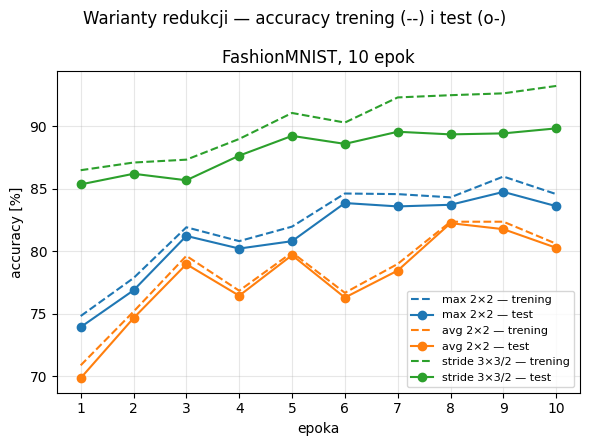

In [10]:
plot_curves([MAIN], [f"{DATASET}, {EPOCHS} epok"], "Warianty redukcji — accuracy trening (--) i test (o-)", "krzywe_obowiazkowe")

In [11]:
base = RESULTS["max 2×2"]
for n in MAIN[1:]:
    r = RESULTS[n]
    d_acc = (r["hist"]["test_acc"][-1] - base["hist"]["test_acc"][-1]) * 100
    print(f"{n:13} vs max 2×2: {d_acc:+.2f} p.p. test acc, {r['params'] - base['params']:+,} parametrów "
          f"(×{r['params'] / base['params']:.2f})")

avg 2×2       vs max 2×2: -3.33 p.p. test acc, +0 parametrów (×1.00)
stride 3×3/2  vs max 2×2: +6.22 p.p. test acc, +46,368 parametrów (×3.36)


## 6. Zakres dodatkowy

### 6A. Okno poolingu: 2×2 vs 3×3
Krok 2 w obu przypadkach, dla 3×3 padding 1. Pozostałe elementy bez zmian (2 bloki, GAP).

In [12]:
WINDOW = ["max 2×2", "max 3×3", "avg 2×2", "avg 3×3"]
for n in WINDOW:
    train_variant(n)
save_table(results_table(WINDOW), "tabela_A_okno")

[max 3×3] epoka  1: train 75.65%  test 75.05%
[max 3×3] epoka  2: train 73.73%  test 73.00%
[max 3×3] epoka  3: train 82.73%  test 82.28%
[max 3×3] epoka  4: train 80.51%  test 80.04%
[max 3×3] epoka  5: train 80.69%  test 79.59%
[max 3×3] epoka  6: train 87.07%  test 85.93%
[max 3×3] epoka  7: train 82.70%  test 81.93%
[max 3×3] epoka  8: train 85.41%  test 84.64%
[max 3×3] epoka  9: train 86.41%  test 84.90%
[max 3×3] epoka 10: train 84.04%  test 82.71%
[avg 3×3] epoka  1: train 70.85%  test 70.17%
[avg 3×3] epoka  2: train 74.54%  test 73.79%
[avg 3×3] epoka  3: train 79.36%  test 78.89%
[avg 3×3] epoka  4: train 77.46%  test 77.40%
[avg 3×3] epoka  5: train 80.36%  test 79.98%
[avg 3×3] epoka  6: train 77.69%  test 77.32%
[avg 3×3] epoka  7: train 76.41%  test 76.19%
[avg 3×3] epoka  8: train 80.74%  test 80.48%
[avg 3×3] epoka  9: train 81.87%  test 81.01%
[avg 3×3] epoka 10: train 81.92%  test 81.69%


,wariant,parametry,parametry głowicy,"mapa przed głowicą [C, H, W]",train acc [%],test acc [%],przerwa train–test [p.p.],maks. test acc* [%] (epoka)
0,max 2×2,19658,650,"[64, 7, 7]",84.56,83.60,0.96,84.74 (9)
1,max 3×3,19658,650,"[64, 7, 7]",84.04,82.71,1.33,85.93 (6)
2,avg 2×2,19658,650,"[64, 7, 7]",80.59,80.27,0.33,82.24 (8)
3,avg 3×3,19658,650,"[64, 7, 7]",81.92,81.69,0.23,81.69 (10)


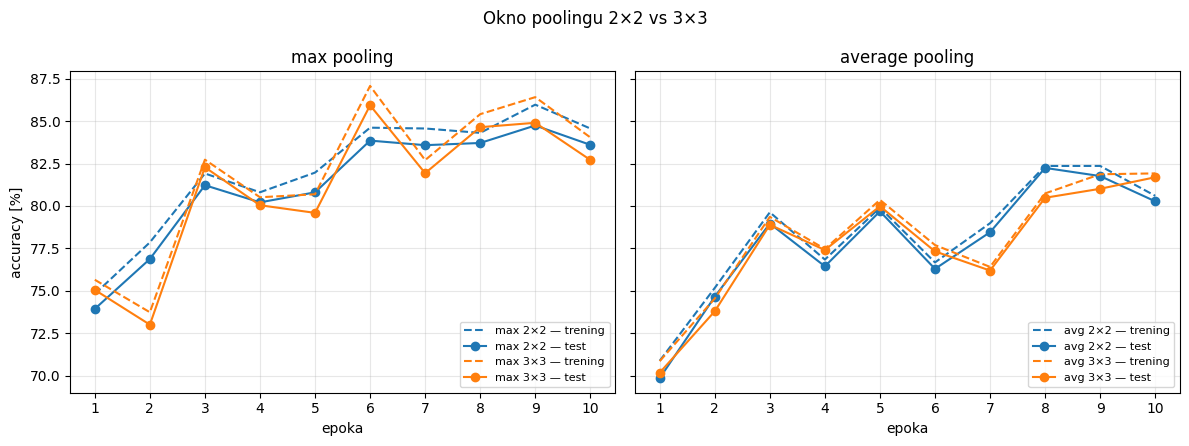

In [13]:
plot_curves([WINDOW[:2], WINDOW[2:]], ["max pooling", "average pooling"], "Okno poolingu 2×2 vs 3×3", "krzywe_A_okno")

### 6B. Głowica: GAP + Linear vs Flatten + Linear
Porównanie dla każdego z trzech wariantów redukcji: liczba parametrów głowicy, accuracy, przerwa train–test.

In [14]:
HEAD = ["max 2×2", "max + flatten", "avg 2×2", "avg + flatten", "stride 3×3/2", "stride + flatten"]
for n in HEAD:
    train_variant(n)
save_table(results_table(HEAD), "tabela_B_glowica")

[max + flatten] epoka  1: train 87.21%  test 85.63%
[max + flatten] epoka  2: train 91.64%  test 89.78%
[max + flatten] epoka  3: train 93.10%  test 91.11%
[max + flatten] epoka  4: train 93.95%  test 91.42%
[max + flatten] epoka  5: train 94.24%  test 91.46%
[max + flatten] epoka  6: train 94.72%  test 91.44%
[max + flatten] epoka  7: train 93.75%  test 90.16%
[max + flatten] epoka  8: train 95.59%  test 91.74%
[max + flatten] epoka  9: train 95.01%  test 90.89%
[max + flatten] epoka 10: train 95.24%  test 90.45%
[avg + flatten] epoka  1: train 89.00%  test 88.18%
[avg + flatten] epoka  2: train 90.89%  test 89.62%
[avg + flatten] epoka  3: train 91.81%  test 90.31%
[avg + flatten] epoka  4: train 92.75%  test 91.11%
[avg + flatten] epoka  5: train 93.27%  test 91.48%
[avg + flatten] epoka  6: train 93.18%  test 91.19%
[avg + flatten] epoka  7: train 92.66%  test 90.76%
[avg + flatten] epoka  8: train 94.25%  test 91.88%
[avg + flatten] epoka  9: train 94.39%  test 92.16%
[avg + flatt

,wariant,parametry,parametry głowicy,"mapa przed głowicą [C, H, W]",train acc [%],test acc [%],przerwa train–test [p.p.],maks. test acc* [%] (epoka)
0,max 2×2,19658,650,"[64, 7, 7]",84.56,83.60,0.96,84.74 (9)
1,max + flatten,50378,31370,"[64, 7, 7]",95.24,90.45,4.79,91.74 (8)
2,avg 2×2,19658,650,"[64, 7, 7]",80.59,80.27,0.33,82.24 (8)
3,avg + flatten,50378,31370,"[64, 7, 7]",94.98,92.06,2.92,92.16 (9)
4,stride 3×3/2,66026,650,"[64, 7, 7]",93.21,89.82,3.39,89.82 (10)
5,stride + flatten,96746,31370,"[64, 7, 7]",98.09,91.59,6.50,91.71 (6)


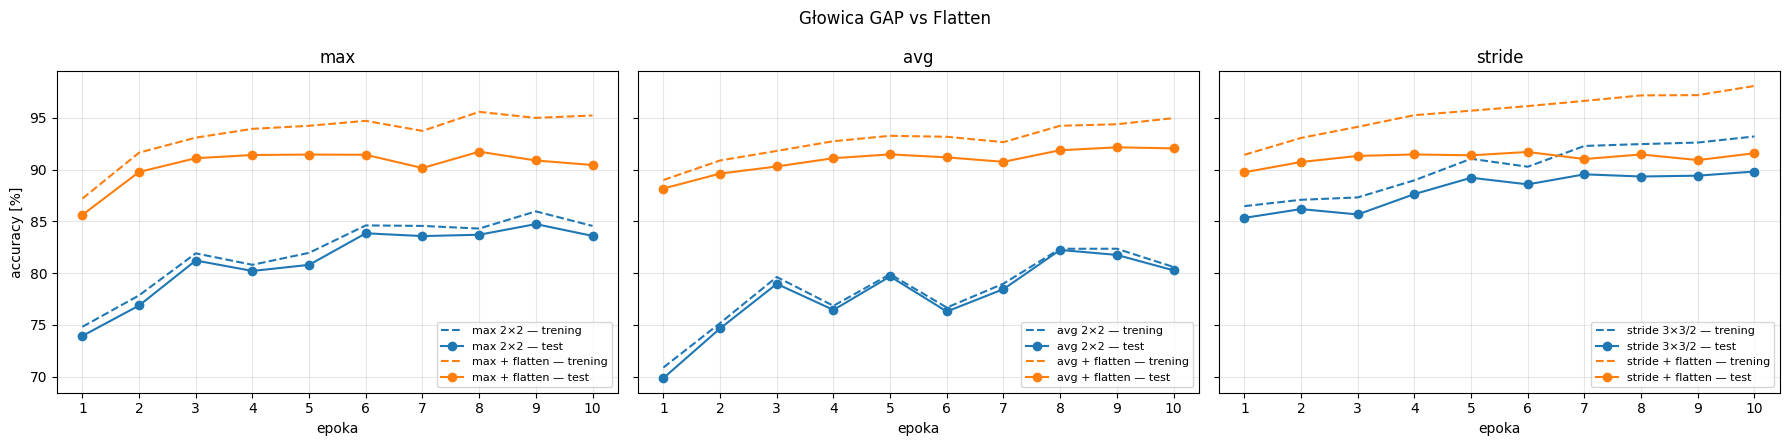

In [15]:
plot_curves([HEAD[0:2], HEAD[2:4], HEAD[4:6]], ["max", "avg", "stride"], "Głowica GAP vs Flatten", "krzywe_B_glowica")

### 6C. Liczba bloków splot–redukcja: 1, 2, 3


In [16]:
BLOCKS = ["max, 1 blok", "max 2×2", "max, 3 bloki",
          "avg, 1 blok", "avg 2×2", "avg, 3 bloki",
          "stride, 1 blok", "stride 3×3/2", "stride, 3 bloki"]
for n in BLOCKS:
    train_variant(n)
save_table(results_table(BLOCKS), "tabela_C_bloki")

[max, 1 blok] epoka  1: train 45.58%  test 45.20%
[max, 1 blok] epoka  2: train 51.54%  test 51.88%
[max, 1 blok] epoka  3: train 55.42%  test 55.62%
[max, 1 blok] epoka  4: train 58.09%  test 57.99%
[max, 1 blok] epoka  5: train 59.24%  test 59.47%
[max, 1 blok] epoka  6: train 60.45%  test 60.52%
[max, 1 blok] epoka  7: train 62.08%  test 62.14%
[max, 1 blok] epoka  8: train 61.90%  test 61.48%
[max, 1 blok] epoka  9: train 63.69%  test 63.56%
[max, 1 blok] epoka 10: train 64.05%  test 63.89%
[max, 3 bloki] epoka  1: train 88.20%  test 86.93%
[max, 3 bloki] epoka  2: train 87.79%  test 86.20%
[max, 3 bloki] epoka  3: train 90.64%  test 88.76%
[max, 3 bloki] epoka  4: train 91.33%  test 89.33%
[max, 3 bloki] epoka  5: train 92.00%  test 89.75%
[max, 3 bloki] epoka  6: train 90.90%  test 88.33%
[max, 3 bloki] epoka  7: train 93.36%  test 90.37%
[max, 3 bloki] epoka  8: train 94.20%  test 90.56%
[max, 3 bloki] epoka  9: train 94.41%  test 90.65%
[max, 3 bloki] epoka 10: train 93.16%  te

,wariant,parametry,parametry głowicy,"mapa przed głowicą [C, H, W]",train acc [%],test acc [%],przerwa train–test [p.p.],maks. test acc* [%] (epoka)
0,"max, 1 blok",714,330,"[32, 14, 14]",64.05,63.89,0.16,63.89 (10)
1,max 2×2,19658,650,"[64, 7, 7]",84.56,83.60,0.96,84.74 (9)
2,"max, 3 bloki",94410,1290,"[128, 3, 3]",93.16,89.34,3.82,90.65 (9)
3,"avg, 1 blok",714,330,"[32, 14, 14]",63.46,63.39,0.07,63.39 (10)
4,avg 2×2,19658,650,"[64, 7, 7]",80.59,80.27,0.33,82.24 (8)
5,"avg, 3 bloki",94410,1290,"[128, 3, 3]",91.72,89.93,1.80,90.42 (9)
6,"stride, 1 blok",10026,330,"[32, 14, 14]",78.98,79.00,-0.02,79.00 (10)
7,stride 3×3/2,66026,650,"[64, 7, 7]",93.21,89.82,3.39,89.82 (10)
8,"stride, 3 bloki",288618,1290,"[128, 4, 4]",98.38,92.31,6.07,92.31 (10)


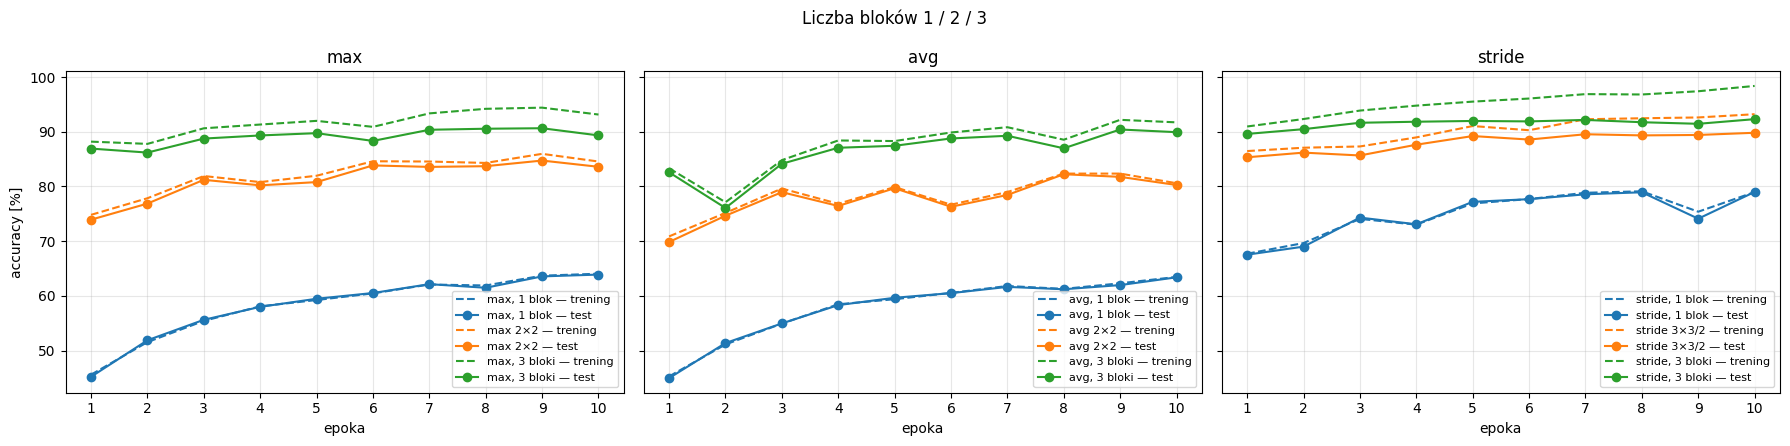

In [17]:
plot_curves([BLOCKS[0:3], BLOCKS[3:6], BLOCKS[6:9]], ["max", "avg", "stride"], "Liczba bloków 1 / 2 / 3", "krzywe_C_bloki")

Pobranie wyników


In [18]:
shutil.make_archive(OUT_DIR, "zip", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))
try:
    from google.colab import files
    files.download(f"{OUT_DIR}.zip")
except ImportError:
    print(f"Archiwum: {OUT_DIR}.zip")

['krzywe_A_okno.png', 'krzywe_B_glowica.png', 'krzywe_C_bloki.png', 'krzywe_obowiazkowe.png', 'tabela_A_okno.csv', 'tabela_B_glowica.csv', 'tabela_C_bloki.csv', 'tabela_obowiazkowa.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>